# Proyecto Melbourne Housing · Random Forest

Respondemos a las preguntas del `README.md` con un **Random Forest** (S06): muchos árboles de decisión entrenados con muestras aleatorias; la predicción es la media de todos.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")

## 1. Datos

`melbourne_limpio.csv` ya está limpio. Pasamos el texto a columnas 0/1 con `get_dummies` y separamos 80 % entrenamiento / 20 % prueba.

In [12]:
from pathlib import Path

BASE = Path.cwd().parent
CLEAN_FILE = BASE / "datasets" / "melbourne_limpio.csv"
df = pd.read_csv(CLEAN_FILE)

df_modelo = pd.get_dummies(df, columns=["Type", "Suburb", "Method", "SellerG"], drop_first=True)
print(str(df_modelo.shape[0]) + "  " + str(df_modelo.shape[1]))
#print(df_modelo.head(4))
X = df_modelo.drop("Price", axis=1)
y = df_modelo["Price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"{len(df)} viviendas | {df.shape[1]} columnas")

27246  708
27246 viviendas | 15 columnas


## 2. Elegir la profundidad (curva de error, como en S05)

Si el error de prueba deja de bajar mientras el de entrenamiento sigue bajando, hay sobreajuste.

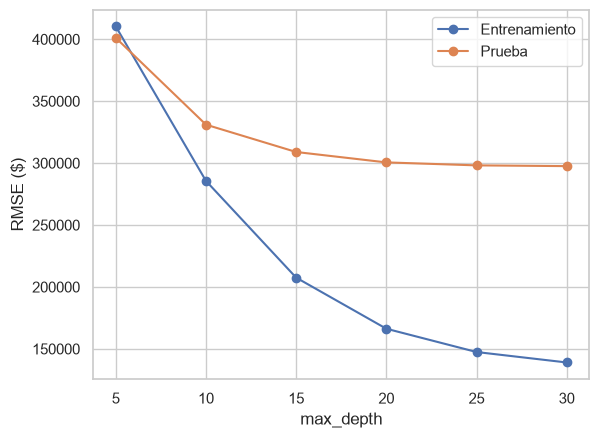

Mejor profundidad: 30


In [15]:
profundidades = [5, 10, 15, 20, 25, 30]
rmse_train, rmse_test = [], []

for d in profundidades:
    rf = RandomForestRegressor(n_estimators=100, max_depth=d, random_state=42, n_jobs=-1).fit(X_train, y_train)
    rmse_train.append(np.sqrt(mean_squared_error(y_train, rf.predict(X_train))))
    rmse_test.append(np.sqrt(mean_squared_error(y_test, rf.predict(X_test))))

plt.plot(profundidades, rmse_train, "o-", label="Entrenamiento")
plt.plot(profundidades, rmse_test, "o-", label="Prueba")
plt.xlabel("max_depth"); plt.ylabel("RMSE ($)"); plt.legend()
plt.show()

mejor_profundidad = profundidades[np.argmin(rmse_test)]
print(f"Mejor profundidad: {mejor_profundidad}")

## 3. Modelo final y validación cruzada (5 folds)

In [16]:
modelo_rf = RandomForestRegressor(n_estimators=300, max_depth=mejor_profundidad, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train, y_train)
pred_test = modelo_rf.predict(X_test)

print(f"RMSE prueba: {np.sqrt(mean_squared_error(y_test, pred_test)):,.0f} $")
print(f"MAE prueba:  {mean_absolute_error(y_test, pred_test):,.0f} $")
print(f"R² prueba:   {r2_score(y_test, pred_test):.3f}")

# Validación cruzada: 5 entrenamientos con una parte distinta de prueba cada vez
r2_cv = cross_val_score(RandomForestRegressor(n_estimators=100, max_depth=mejor_profundidad, random_state=42, n_jobs=-1),
                        X, y, cv=5, scoring="r2")
print(f"R² en los 5 folds: {np.round(r2_cv, 3)} -> media {r2_cv.mean():.3f}")

RMSE prueba: 295,634 $
MAE prueba:  181,026 $
R² prueba:   0.778
R² en los 5 folds: [0.722 0.686 0.724 0.714 0.734] -> media 0.716


## 1.1 · Predice el precio medio de una vivienda

Precio medio real:     1,046,728 $
Precio medio predicho: 1,040,336 $


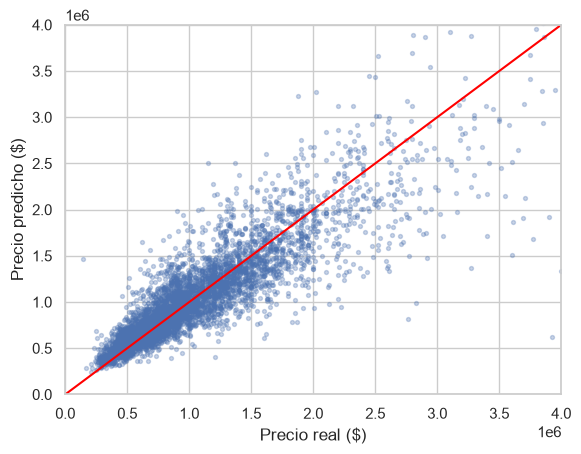

In [17]:
print(f"Precio medio real:     {y_test.mean():,.0f} $")
print(f"Precio medio predicho: {pred_test.mean():,.0f} $")

plt.scatter(y_test, pred_test, alpha=0.3, s=8)
plt.plot([0, 4e6], [0, 4e6], color="red")
plt.xlim(0, 4e6); plt.ylim(0, 4e6)
plt.xlabel("Precio real ($)"); plt.ylabel("Precio predicho ($)")
plt.show()

**Conclusión.** El modelo explica el **78 %** de la variación del precio en prueba (R² 0,778) y se equivoca de media unos **181.000 $** (MAE). En la validación cruzada el R² se mantiene entre 0,69 y 0,73 en los 5 folds (media 0,72), así que el resultado es estable. El precio medio predicho (1.040.336 $) es casi igual al real (1.046.728 $). Donde más falla es en las viviendas muy caras, que tiende a predecir por debajo.

*Nota sobre la profundidad:* a partir de `max_depth=20` el error de prueba casi no baja (de ~300.000 $ a ~297.000 $), mientras el de entrenamiento sigue cayendo. Ganó 30, el extremo de la lista, pero la mejora es mínima.

## 1.2 · ¿Qué características encarecen una vivienda?

`feature_importances_` (S05/S06). Sumamos las columnas que vienen de la misma variable (todas las `Suburb_...` juntas).

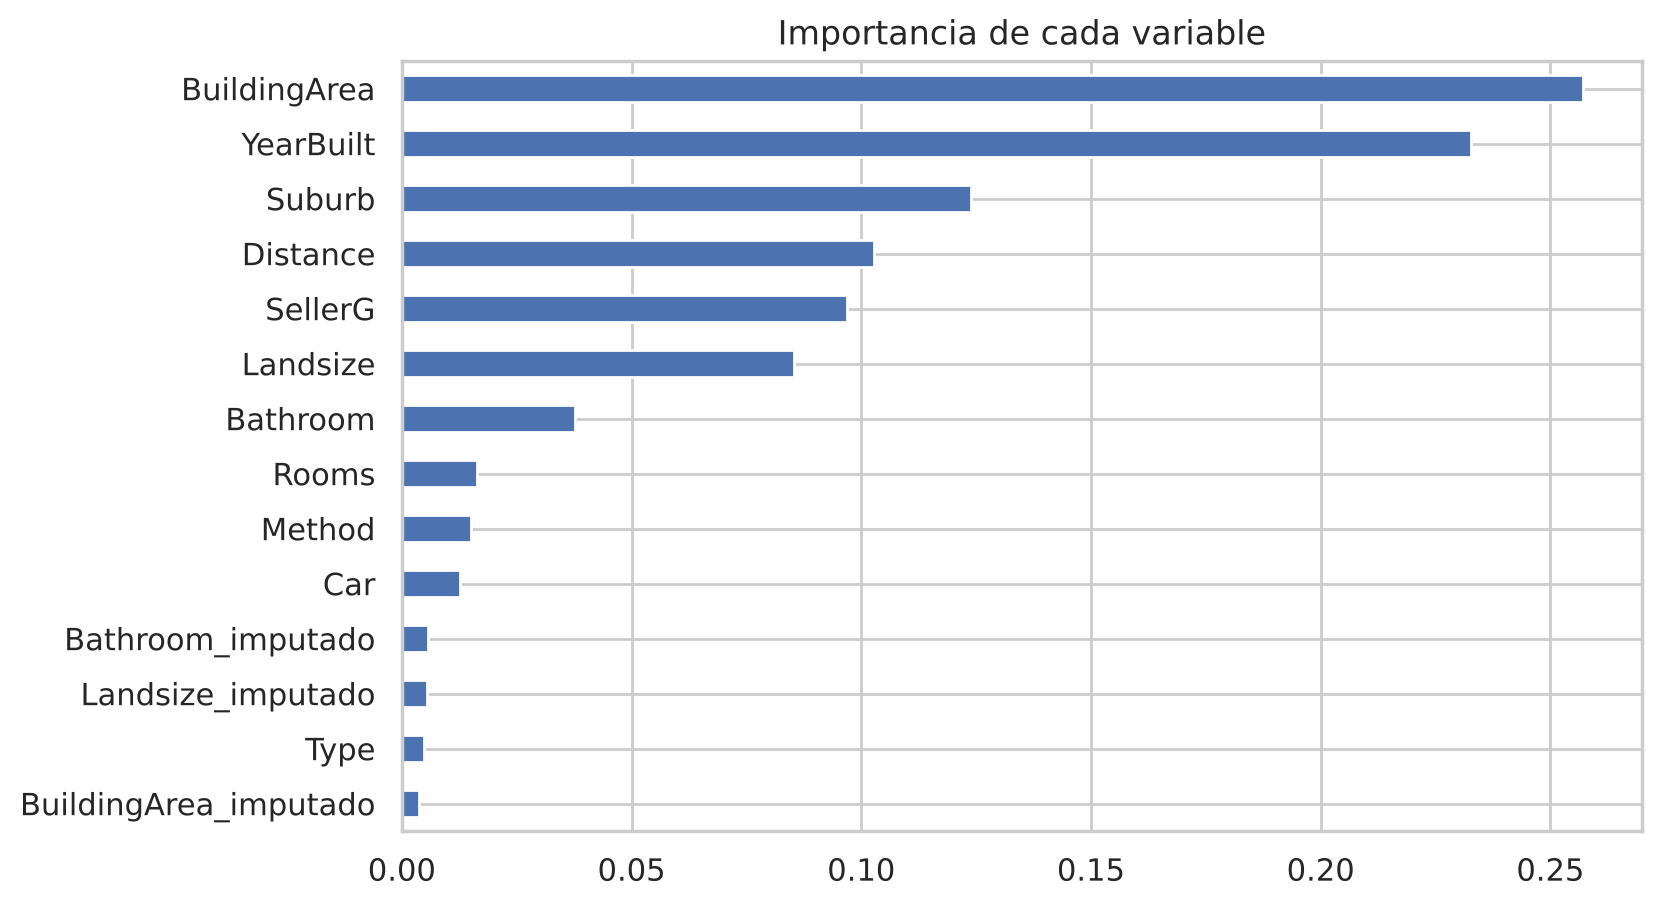

BuildingArea    0.54
Distance       -0.19
YearBuilt      -0.43
Landsize        0.05
Rooms           0.50
Price           1.00
Name: Price, dtype: float64

In [ ]:
importancias = pd.Series(modelo_rf.feature_importances_, index=X.columns)
importancias.index = [c.split("_")[0] if c.split("_")[0] in ["Type", "Suburb", "Method", "SellerG"] else c
                      for c in importancias.index]
importancias = importancias.groupby(level=0).sum().sort_values()

importancias.plot(kind="barh", figsize=(8, 5), title="Importancia de cada variable")
plt.show()

# ¿Sube o baja el precio? Correlación con el precio
df[["BuildingArea", "Distance", "YearBuilt", "Landsize", "Rooms", "Price"]].corr(method="spearman")["Price"].round(2)

**Conclusión.** Lo que más usa el modelo es la **superficie construida**, seguida del **año de construcción**, el **suburbio**, la **distancia al centro**, la **agencia** (`SellerG`) y la **parcela**. Con la correlación vemos la dirección: más m² y más habitaciones → más caro; más lejos del centro → más barato. El año sale con signo negativo (las casas antiguas son más caras) porque las casas antiguas están en los barrios céntricos: en realidad refleja la ubicación.

## 1.3 · ¿Qué tipo de vivienda genera más beneficio?

Sin costes en el dataset, usamos el **precio predicho por m² construido** (solo viviendas con superficie original, no imputada).

In [ ]:
prueba = df.loc[X_test.index].copy()
prueba["precio_m2"] = pred_test / prueba["BuildingArea"]
prueba = prueba[(prueba["BuildingArea_imputado"] == 0) & (prueba["BuildingArea"] >= 20)]

prueba.groupby("Type")[["precio_m2", "Price", "BuildingArea", "Landsize", "Distance"]].median().round(0)

,precio_m2,Price,BuildingArea,Landsize,Distance
Type,,,,,
h,7333.0,1020000.0,150.0,574.0,11.0
t,6408.0,840000.0,134.0,211.0,10.0
u,7683.0,550000.0,76.0,601.0,6.0


**Conclusión.** Por m² construido, las **unidades** (u) son las que más valen (~7.700 $/m²), seguidas de las **casas** (h, ~7.300 $/m²) y por último los **townhouses** (t, ~6.400 $/m²). Las unidades están más cerca del centro (6 km) y son pequeñas, por eso el m² sale caro. Las casas tienen el precio total más alto porque incluyen más suelo. Los townhouses tienen casi tanta superficie como una casa pero mucho menos suelo, y por eso rinden menos.

## 1.4 · ¿Es rentable un terreno sin construir?

Supuestos: obra a 2.200 $/m², construir el 50 % de la parcela (máx. 200 m²) y 12 % de permisos y financiación. **Margen = (valor nuevo − coste) / coste.** Rentable si > 15 %.

⚠️ No hay terrenos vacíos en el dataset: usamos casas con parcela ≥ 200 m² sin superficie construida original, así que equivale a comprar, derribar y construir.

In [ ]:
parcelas = df[(df["Type"] == "h") & (df["BuildingArea_imputado"] == 1) & (df["Landsize_imputado"] == 0) & (df["Landsize"] >= 200)].copy()

m2_nuevos = np.minimum(parcelas["Landsize"] * 0.5, 200)
coste = (parcelas["Price"] + m2_nuevos * 2200) * 1.12

# La misma parcela con una casa nueva
nueva = parcelas.assign(BuildingArea=m2_nuevos, YearBuilt=2026, BuildingArea_imputado=0).drop(columns="Price")
X_nueva = pd.get_dummies(nueva, columns=["Type", "Suburb", "Method", "SellerG"]).reindex(columns=X.columns, fill_value=0)

parcelas["margen_pct"] = (modelo_rf.predict(X_nueva) - coste) / coste * 100

print(f"{len(parcelas)} parcelas | margen mediano {parcelas['margen_pct'].median():.1f} % | rentables: {(parcelas['margen_pct'] > 15).mean() * 100:.1f} %")

por_suburbio = parcelas.groupby("Suburb")["margen_pct"].agg(["count", "median"])
por_suburbio[por_suburbio["count"] >= 5].sort_values("median", ascending=False).round(1).iloc[[0, 1, 2, 3, 4, -5, -4, -3, -2, -1]]

6009 parcelas | margen mediano -33.1 % | rentables: 0.3 %


,count,median
Suburb,,
Brooklyn,5,-5.9
Dallas,6,-11.3
Dingley Village,14,-13.0
Heidelberg West,46,-13.4
Spotswood,12,-15.5
Prahran,17,-53.1
St Kilda,16,-53.2
Mont Albert,16,-53.3
Middle Park,6,-57.9


**Conclusión.** Con estos supuestos **no es rentable**: el margen mediano es del **−33 %** y solo un 0,3 % de las parcelas supera el 15 %. Ningún suburbio llega a margen positivo; los menos malos son zonas con suelo barato (Brooklyn, Dallas, Heidelberg West) y los peores, zonas con suelo muy caro (Albert Park, Middle Park, St Kilda). Ojo: el modelo da menos valor a lo nuevo (lo nuevo suele estar lejos del centro), así que el resultado puede ser algo pesimista.

## Mapa

Viviendas de prueba sobre el mapa de Melbourne: 🟢 más de un 10 % por debajo de la predicción, 🔵 ±10 %, 🔴 más de un 10 % por encima. Clic en un punto para ver sus datos.

In [ ]:
import folium
from folium.plugins import MarkerCluster

# Coordenadas del dataset original (mismo orden que el limpio, sin las filas sin precio)
original = pd.read_csv("Melbourne_housing_FULL.csv").dropna(subset=["Price"]).reset_index(drop=True)
clave = ["Suburb", "Rooms", "Type", "Price", "Method", "SellerG"]
filas_original = original[clave].values.tolist()
posiciones, j = [], 0
for fila in df[clave].values.tolist():
    while filas_original[j] != fila:
        j += 1
    posiciones.append(j)
    j += 1
df[["Address", "Lat", "Lon"]] = original.loc[posiciones, ["Address", "Lattitude", "Longtitude"]].values

casas = df.loc[X_test.index].assign(pred=pred_test).dropna(subset=["Lat"])
casas["dif"] = (casas["Price"] - casas["pred"]) / casas["pred"] * 100

mapa = folium.Map(location=[-37.81, 144.96], zoom_start=11, tiles=None)
esri = "https://server.arcgisonline.com/ArcGIS/rest/services/{}/MapServer/tile/{{z}}/{{y}}/{{x}}"
folium.TileLayer(esri.format("World_Street_Map"), attr="Esri", name="Calles").add_to(mapa)
folium.TileLayer(esri.format("World_Imagery"), attr="Esri", name="Satélite").add_to(mapa)
grupo = MarkerCluster().add_to(mapa)

for _, c in casas.iterrows():
    color = "#1baf7a" if c["dif"] < -10 else "#d03b3b" if c["dif"] > 10 else "#2a78d6"
    texto = (f"<b>{c['Address']}</b>, {c['Suburb']}<br>Real: {c['Price']:,.0f} $<br>"
             f"Predicho: {c['pred']:,.0f} $ ({c['dif']:+.0f} %)<br>"
             f"{c['Rooms']:.0f} hab · {c['BuildingArea']:.0f} m² · {c['YearBuilt']:.0f}")
    folium.CircleMarker([c["Lat"], c["Lon"]], radius=6, color=color, fill=True, fill_opacity=0.8,
                        popup=folium.Popup(texto, max_width=250)).add_to(grupo)

folium.LayerControl().add_to(mapa)
mapa.save("melbourne_mapa.html")
mapa

## Conclusiones

| Pregunta | Respuesta |
|---|---|
| ¿Se puede predecir el precio? | Sí: R² 0,78 en prueba y 0,72 de media en validación cruzada. |
| 1.1 Precio medio | Predicho 1.040.336 $ frente a 1.046.728 $ reales. |
| 1.2 Qué encarece | Superficie construida, ubicación (suburbio, distancia, antigüedad) y tamaño de parcela. |
| 1.3 Tipo más rentable | Por m²: unidades. Por precio total: casas. Townhouses, los últimos. |
| 1.4 Terreno | No rentable con estos supuestos (margen mediano −33 %). |